# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Habrian Daffa Dwiyandana
- **Email:** daffahabrian@gmail.com
- **ID Dicoding:** habrii

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Seberapa besar peningkatan rata-rata jumlah penyewaan sepeda pada jam sibuk berangkat kerja (08:00) dan pulang kerja (17:00) di hari kerja selama musim gugur tahun 2012 dibandingkan tahun 2011, untuk membantu tim operasional menyesuaikan kapasitas armada harian?
- **Pertanyaan 2:** Di antara suhu udara, kelembaban, dan kecepatan angin, faktor cuaca manakah yang memiliki korelasi negatif terkuat terhadap jumlah penyewa kasual pada akhir pekan dan hari libur sepanjang periode 2011–2012, agar tim pemasaran dapat menyusun strategi promosi berbasis cuaca?
- ...

## Import Semua Packages/Library yang Digunakan

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi agar rapi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Data Wrangling

### Gathering Data

#### Load df Dataset Bike Sharing (day.csv dan hour.csv)

In [36]:
day_df = pd.read_csv ("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Preview day_df:")
display(day_df.head())

print("Preview hour_df:")
display(hour_df.head())

Preview day_df:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Preview hour_df:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset ini terdiri dari dua tabel utama, yaitu day_df untuk rekapitulasi penyewaan harian (731 baris, 16 kolom) dan hour_df untuk rincian transaksi per jam (17.379 baris, 17 kolom)

- Keduanya menyimpan data historis operasional dari 1 Januari 2011 hingga 31 Desember 2012, lengkap dengan informasi kalender dan kondisi cuaca

### Assessing Data

#### Identifying masalah kualitas data (Tipe Data, anomali data dan Outlier)

In [37]:
print (" info day_df ")
display(day_df.info())

print (" info hour_df ")
display(hour_df.info())

print("\n Missing Value & Duplikasi ")
print(f"day_df  -> Missing value: {day_df.isna().sum().sum()} | Duplikat: {day_df.duplicated().sum()}")
print(f"hour_df -> Missing value: {hour_df.isna().sum().sum()} | Duplikat: {hour_df.duplicated().sum()}")

print("\n Pemeriksaan Outlier Menggunakan Metode IQR ")
def cek_outlier(df, kolom):
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)
    outliers = df[(df[kolom] < batas_bawah) | (df[kolom] > batas_atas)]
    return len(outliers)

print("Jumlah baris outlier 'casual' (hour_df):", cek_outlier(hour_df, 'casual'))
print("Jumlah baris outlier 'registered' (hour_df):", cek_outlier(hour_df, 'registered'))
print("Jumlah baris outlier 'cnt' (hour_df):", cek_outlier(hour_df, 'cnt'))

print("\n Pemeriksaan Anomali Kelembaban Udara (hum == 0) ")
print("Jumlah baris 'hum' == 0 (day_df):", (day_df["hum"] == 0).sum())
print("Jumlah baris 'hum' == 0 (hour_df):", (hour_df["hum"] == 0).sum())

display(hour_df[hour_df["hum"] == 0][["dteday", "hr", "season", "weathersit", "hum"]].head())




 info day_df 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


None

 info hour_df 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


None


 Missing Value & Duplikasi 
day_df  -> Missing value: 0 | Duplikat: 0
hour_df -> Missing value: 0 | Duplikat: 0

 Pemeriksaan Outlier Menggunakan Metode IQR 
Jumlah baris outlier 'casual' (hour_df): 1192
Jumlah baris outlier 'registered' (hour_df): 680
Jumlah baris outlier 'cnt' (hour_df): 505

 Pemeriksaan Anomali Kelembaban Udara (hum == 0) 
Jumlah baris 'hum' == 0 (day_df): 1
Jumlah baris 'hum' == 0 (hour_df): 22


,dteday,hr,season,weathersit,hum
1551,2011-03-10,0,1,3,0.0
1552,2011-03-10,1,1,3,0.0
1553,2011-03-10,2,1,3,0.0
1554,2011-03-10,5,1,3,0.0
1555,2011-03-10,6,1,3,0.0


**Steps to Take:**
- Kolom tanggal (dteday) pada kedua tabel masih bertipe object (string) dan perlu diubah ke tipe datetime64 agar dapat dianalisis secara temporal

- Ditemukan 1 baris di day_df dan 22 baris di hour_df yang nilai kelembabannya (hum) tercatat 0.0. Berdasarkan pemeriksaan data, seluruh anomali ini terjadi pada 10 Maret 2011 saat kondisi cuaca hujan/salju ringan (weathersit = 3), yang secara meteorologis tidak logis. Solusinya adalah mengubah nilai 0 menjadi NaN, kemudian melakukan imputasi menggunakan nilai median berdasarkan kelompok musim (season) dan kondisi cuaca (weathersit) yang sama

- Pengecekan menggunakan metode IQR (*Interquartile Range*) mendeteksi adanya ratusan hingga ribuan baris *outlier* pada kolom casual, registered, dan cnt. Namun, nilai-nilai ekstrem ini dipertahankan karena merefleksikan lonjakan permintaan alami di lapangan (seperti saat hari libur nasional atau akhir pekan yang cerah), bukan kesalahan pencatatan sistem



**Insight:** (Opsional)
- Berdasarkan pengecekan menggunakan fungsi .info(), diketahui bahwa jumlah data pada day_df adalah 731 baris dan hour_df adalah 17.379 baris. Tidak ditemukan adanya *missing value* maupun data ganda (*duplikat*) pada kedua tabel. Namun, terdapat ketidaksesuaian tipe data pada kolom tanggal (dteday) yang masih terbaca sebagai *object* (string)

- Melalui pemeriksaan eksplisit pada kolom kelembaban (hum), ditemukan anomali berupa nilai 0.0 (sebanyak 1 baris pada day_df dan 22 baris pada hour_df). Berdasarkan penelusuran data spesifik tanggal, seluruh anomali nilai nol tersebut tercatat pada 10 Maret 2011 saat kondisi cuaca sedang hujan atau salju ringan (weathersit = 3), yang secara fisik/meteorologis tidak logis untuk tingkat kelembaban udara

- Berdasarkan hasil pengujian statistik menggunakan metode batas IQR (*Interquartile Range*), terdeteksi adanya ratusan hingga ribuan baris data *outlier* pada kolom jumlah penyewaan (casual, registered, dan cnt). Nilai-nilai ekstrem ini diputuskan untuk **dipertahankan** karena mencerminkan lonjakan permintaan alami di dunia nyata (seperti lonjakan pengunjung saat libur nasional atau akhir pekan yang cerah), dan bukan merupakan kesalahan pencatatan atau kerusakan sistem (*error*)

### Cleaning Data

#### Membersihkan Data dari anomali kelembaban dan memperbaiki Tipe Data

In [38]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

desc_before = hour_df['hum'].describe()

for df in [day_df, hour_df]:
  df["hum"] = df["hum"].replace(0, np.nan)
  df["hum"] = df["hum"].fillna(df.groupby(["season", "weathersit"])["hum"].transform("median"))

season_map = {1: "Spring", 2:"Summer", 3: "Fall", 4: "Winter"}
year_map = {0: 2011, 1: 2012}

for df in [day_df, hour_df]:
    df["season_label"] = df["season"].map(season_map)
    df["year"] = df["yr"].map(year_map)
    df["temp_c"] = df["temp"] * 41
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67

desc_after = hour_df['hum'].describe()
df_banding = pd.concat([desc_before, desc_after], axis=1, keys=['Sebelum Imputasi', 'Sesudah Imputasi'])

print(" Pengecekan Hasil Cleaning")
print(" Tipe data dteday:", hour_df["dteday"].dtype)
print("Sisa hum == 0 di hour_df:", (hour_df["hum"] == 0).sum())
display(df_banding)

# Pengecekan ulang sesuai
print("\n Cek Ulang Info Dataset Setelah Cleaning ")
display(hour_df.info())

print("\n Cek Ulang Missing Value Setelah Cleaning ")
print(hour_df.isna().sum())

hour_df.to_csv("main_data.csv", index=False)
print("\n File 'main_data.csv' berhasil dibuat dan disimpan!")

 Pengecekan Hasil Cleaning
 Tipe data dteday: datetime64[ns]
Sisa hum == 0 di hour_df: 0


,Sebelum Imputasi,Sesudah Imputasi
count,17379.000000,17379.000000
mean,0.627229,0.628306
std,0.192930,0.191809
min,0.000000,0.080000
25%,0.480000,0.480000
50%,0.630000,0.630000
75%,0.780000,0.780000
max,1.000000,1.000000



 Cek Ulang Info Dataset Setelah Cleaning 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        17379 non-null  int64         
 1   dteday         17379 non-null  datetime64[ns]
 2   season         17379 non-null  int64         
 3   yr             17379 non-null  int64         
 4   mnth           17379 non-null  int64         
 5   hr             17379 non-null  int64         
 6   holiday        17379 non-null  int64         
 7   weekday        17379 non-null  int64         
 8   workingday     17379 non-null  int64         
 9   weathersit     17379 non-null  int64         
 10  temp           17379 non-null  float64       
 11  atemp          17379 non-null  float64       
 12  hum            17379 non-null  float64       
 13  windspeed      17379 non-null  float64       
 14  casual         17379 non-nu

None


 Cek Ulang Missing Value Setelah Cleaning 
instant          0
dteday           0
season           0
yr               0
mnth             0
hr               0
holiday          0
weekday          0
workingday       0
weathersit       0
temp             0
atemp            0
hum              0
windspeed        0
casual           0
registered       0
cnt              0
season_label     0
year             0
temp_c           0
hum_pct          0
windspeed_kmh    0
dtype: int64

 File 'main_data.csv' berhasil dibuat dan disimpan!


**Insight:** (Opsional)
- Tipe data tanggal pada kolom dteday telah berhasil diubah menjadi datetime64

- Seluruh anomali kelembaban bernilai 0.0 telah dibersihkan dan diimputasi ulang. Berdasarkan tabel perbandingan statistik sebelum dan sesudah imputasi, nilai rata-rata (*mean*) dan standar deviasi (*std*) pada data kelembaban hampir tidak bergeser (tetap di angka ~0.627), yang membuktikan bahwa metode imputasi median kelompok berhasil memperbaiki data rusak tanpa merusak distribusi asli cuaca

## Exploratory Data Analysis (EDA)

### Mengeksplorasi Pola Penyewaan Sepeda Berdasarkan Jam Sibuk dan Kondisi Cuaca

In [39]:
season_summary = day_df.groupby(["year", "season_label"])["cnt"].agg(["mean", "sum"]).reset_index()
print(" RANGKUMAN PENYEWAAN PER TAHUN & MUSIM ")
display(season_summary)

# pertanyaan 1: jam sibuk musim gugur (08:00 dan 17:00) pada hari kerja
q1_df = hour_df[
    (hour_df["workingday"] == 1) &
    (hour_df["hr"].isin([8, 17])) &
    (hour_df["season_label"] == "Fall")
]

q1_summary = q1_df.groupby(["year", "hr"])["cnt"].agg(["count", "mean", "median", "sum"]).reset_index()
print("\n Rata-Rata Penyewaan Jam Sibuk Musim Gugur (2011 vs 2012) ")
display(q1_summary)

q2_df = hour_df[hour_df["workingday"] == 0][["temp_c", "hum_pct", "windspeed_kmh", "casual"]]
q2_corr = q2_df.corr()

print("\n=== MATRIKS KORELASI CUACA VS PENYEWA (AKHIR PEKAN/LIBUR) ===")
display(q2_corr[["casual"]])

 RANGKUMAN PENYEWAAN PER TAHUN & MUSIM 


,year,season_label,mean,sum
0,2011,Fall,4464.361702,419650
1,2011,Spring,1666.666667,150000
2,2011,Summer,3775.173913,347316
3,2011,Winter,3664.460674,326137
4,2012,Fall,6824.244681,641479
5,2012,Spring,3531.296703,321348
6,2012,Summer,6209.489130,571273
7,2012,Winter,5791.865169,515476



 Rata-Rata Penyewaan Jam Sibuk Musim Gugur (2011 vs 2012) 


,year,hr,count,mean,median,sum
0,2011,8,66,420.106061,424.5,27727
1,2011,17,66,507.424242,541.0,33490
2,2012,8,65,679.384615,687.0,44160
3,2012,17,65,796.661538,833.0,51783



=== MATRIKS KORELASI CUACA VS PENYEWA (AKHIR PEKAN/LIBUR) ===


,casual
temp_c,0.541886
hum_pct,-0.381183
windspeed_kmh,0.089751
casual,1.000000


**Insight:** (Opsional)
- Berdasarkan rangkuman data per tahun dan musim, Musim Gugur (*Fall*) mencatatkan total dan rata-rata penyewaan sepeda tertinggi di kedua tahun (rata-rata 4.464 unit/hari di 2011 dan 6.824 unit/hari di 2012). Hal ini mendasari pemilihan Musim Gugur sebagai fokus utama pada Pertanyaan 1

- Pertanyaan 1: Rata-rata penyewaan sepeda pada jam sibuk hari kerja (*workingday*) di musim gugur mengalami peningkatan yang nyata dari tahun 2011 ke 2012. Jam 08:00 pagi meningkat dari 420,11 menjadi 679,38 unit/jam, dan jam 17:00 sore meningkat dari 507,42 menjadi 796,66 unit/jam

- Pertanyaan 2: Matriks korelasi menunjukkan bahwa pada akhir pekan dan hari libur, kelembaban udara memiliki korelasi negatif terkuat ($r = -0,38$) terhadap jumlah penyewa kasual dibandingkan kecepatan angin ($r = +0,09$), sementara suhu udara memiliki korelasi positif yang cukup kuat ($r = +0,54$)

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Seberapa besar peningkatan rata-rata jumlah penyewaan sepeda pada jam sibuk berangkat kerja (08:00) dan pulang kerja (17:00) di hari kerja selama musim gugur tahun 2012 dibandingkan tahun 2011, untuk membantu tim operasional menyesuaikan kapasitas armada harian?


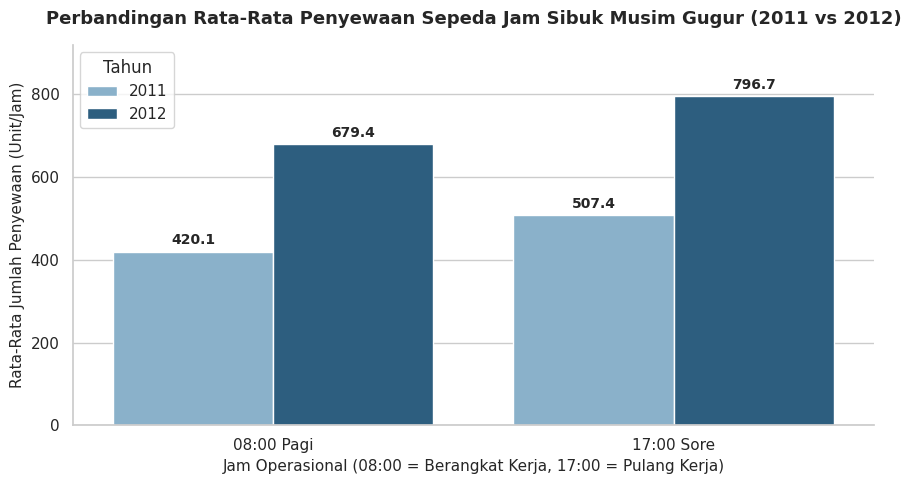

In [40]:

df_q1 = hour_df[
    (hour_df["workingday"] == 1) &
    (hour_df["hr"].isin([8, 17])) &
    (hour_df["season_label"] == "Fall")
]
rekap_q1 = df_q1.groupby(["year", "hr"])["cnt"].agg(["count", "mean", "median", "sum"]).reset_index()

plt.figure(figsize=(9, 5))
ax1 = sns.barplot(
    data=rekap_q1,
    x="hr",
    y="mean",
    hue="year",
    palette=["#7FB3D5", "#1F618D"]
)

for container in ax1.containers:
    ax1.bar_label(container, fmt="%.1f", padding=3, fontsize=10, fontweight="bold")

plt.title("Perbandingan Rata-Rata Penyewaan Sepeda Jam Sibuk Musim Gugur (2011 vs 2012)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Jam Operasional (08:00 = Berangkat Kerja, 17:00 = Pulang Kerja)", fontsize=11)
plt.ylabel("Rata-Rata Jumlah Penyewaan (Unit/Jam)", fontsize=11)
plt.xticks(ticks=[0, 1], labels=["08:00 Pagi", "17:00 Sore"])
plt.ylim(0, 920)
plt.legend(title="Tahun")
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Di antara suhu udara, kelembaban, dan kecepatan angin, faktor cuaca manakah yang memiliki korelasi negatif terkuat terhadap jumlah penyewa kasual pada akhir pekan dan hari libur sepanjang periode 2011–2012, agar tim pemasaran dapat menyusun strategi promosi berbasis cuaca?

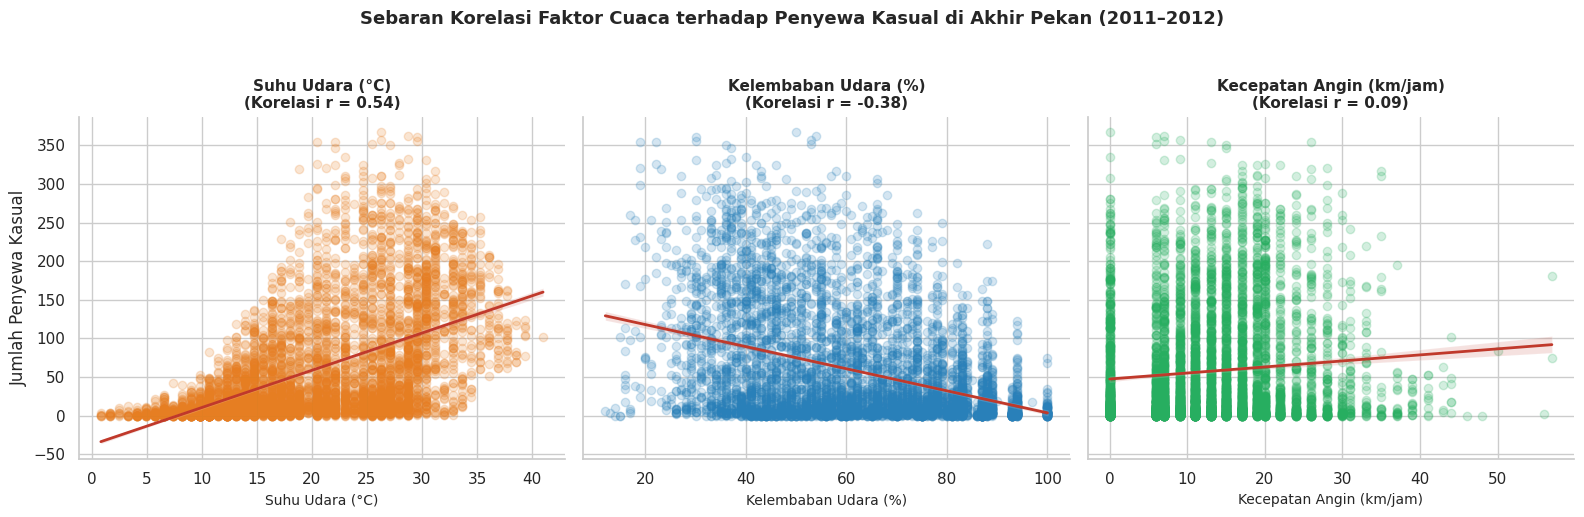

In [41]:

df_q2 = hour_df[hour_df["workingday"] == 0][["temp_c", "hum_pct", "windspeed_kmh", "casual"]]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

faktor_cuaca = [
    ("temp_c", "Suhu Udara (°C)", "#E67E22"),
    ("hum_pct", "Kelembaban Udara (%)", "#2980B9"),
    ("windspeed_kmh", "Kecepatan Angin (km/jam)", "#27AE60")
]

for ax, (kolom, label, warna) in zip(axes, faktor_cuaca):
    sns.regplot(
        data=df_q2,
        x=kolom,
        y="casual",
        ax=ax,
        scatter_kws={"alpha": 0.2, "color": warna},
        line_kws={"color": "#C0392B", "linewidth": 2}
    )
    nilai_korelasi = df_q2[kolom].corr(df_q2["casual"])
    ax.set_title(f"{label}\n(Korelasi r = {nilai_korelasi:.2f})", fontsize=11, fontweight="bold")
    ax.set_xlabel(label, fontsize=10)
    ax.set_ylabel("Jumlah Penyewa Kasual" if ax == axes[0] else "")
    sns.despine(ax=ax)

plt.suptitle("Sebaran Korelasi Faktor Cuaca terhadap Penyewa Kasual di Akhir Pekan (2011–2012)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Diagram batang di atas membandingkan jumlah rata-rata penyewaan sepeda secara spesifik pada pukul 08:00 dan 17:00 saat musim gugur tahun 2011 dan 2012. Terlihat beban pengguna (demand) paling tinggi berpusat pada jam pulang kerja pukul 17:00 di tahun 2012 yang mencapai hampir 800 pengguna per jam. Kenaikan ini terjadi sangat konsisten di kedua jam sibuk tersebut

- Tiga diagram pencar (scatter plot) di atas menampilkan korelasi antara faktor cuaca dan pengguna kasual pada hari libur dan akhir pekan. Meskipun titik sebarannya terlihat sangat lebar (karena data dihitung per jam dan masih tercampur oleh pola jam, seperti dini hari di mana kelembaban tinggi tapi penyewa sedikit), koefisien arah kelembaban (-0.38) menunjukkan tren yang berlawanan. Ini berarti dari ketiga faktor tersebut, kelembaban udara memiliki korelasi negatif terkuat; di mana semakin tinggi persentase kelembaban cuaca, pengguna kasual cenderung semakin berkurang

## Analisis Lanjutan (Opsional)

 Tabel Rata-rata Penyewaan Berdasarkan Klaster Waktu 


,time_cluster,day_type,casual,registered
0,1. Dini Hari (00-05),Akhir Pekan / Libur,8.385630,34.612903
1,1. Dini Hari (00-05),Hari Kerja,2.691277,13.743819
2,2. Jam Sibuk Pagi (06-09),Akhir Pekan / Libur,19.501085,65.498915
3,2. Jam Sibuk Pagi (06-09),Hari Kerja,15.772681,262.136593
4,3. Siang Hari (10-15),Akhir Pekan / Libur,120.781385,218.164502
5,3. Siang Hari (10-15),Hari Kerja,40.830707,138.831378
6,4. Jam Sibuk Sore (16-19),Akhir Pekan / Libur,97.598698,199.741866
7,4. Jam Sibuk Sore (16-19),Hari Kerja,49.182046,365.572718
8,5. Malam Hari (20-23),Akhir Pekan / Libur,32.527174,97.170652
9,5. Malam Hari (20-23),Hari Kerja,22.232932,143.543173


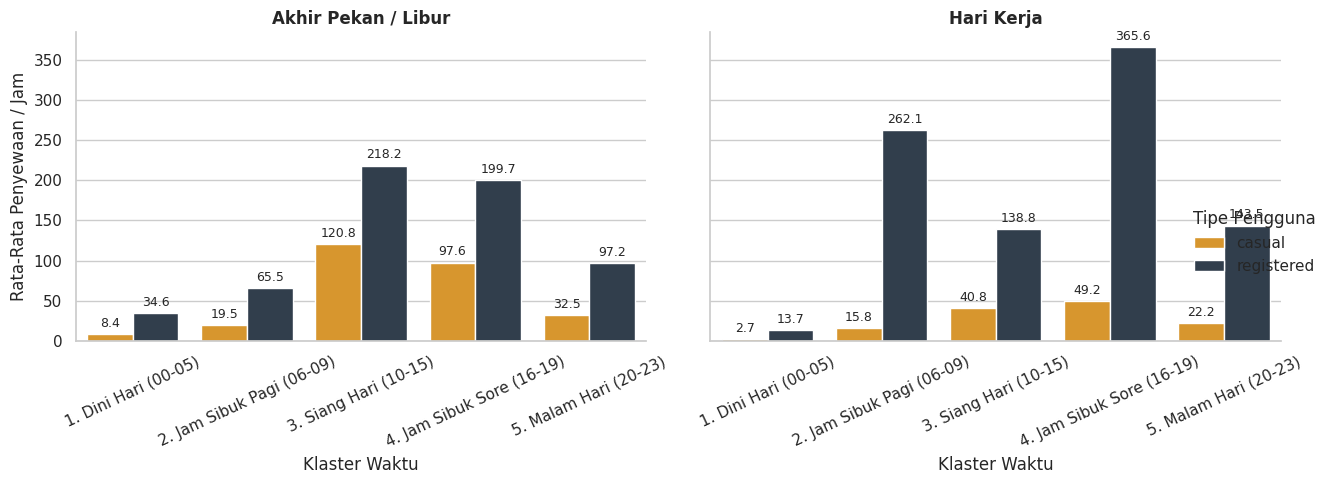

In [42]:
def categorize_time(hr):
    if 0 <= hr <= 5:
        return "1. Dini Hari (00-05)"
    elif 6 <= hr <= 9:
        return "2. Jam Sibuk Pagi (06-09)"
    elif 10 <= hr <= 15:
        return "3. Siang Hari (10-15)"
    elif 16 <= hr <= 19:
        return "4. Jam Sibuk Sore (16-19)"
    else:
        return "5. Malam Hari (20-23)"

hour_df["time_cluster"] = hour_df["hr"].apply(categorize_time)
hour_df["day_type"] = hour_df["workingday"].map({0: "Akhir Pekan / Libur", 1: "Hari Kerja"})

cluster_agg = hour_df.groupby(["time_cluster", "day_type"])[["casual", "registered"]].mean().reset_index()

print(" Tabel Rata-rata Penyewaan Berdasarkan Klaster Waktu ")
display(cluster_agg)

cluster_melted = cluster_agg.melt(
    id_vars=["time_cluster", "day_type"],
    value_vars=["casual", "registered"],
    var_name="Tipe Pengguna",
    value_name="Rata-Rata Penyewaan"
)

g = sns.catplot(
    data=cluster_melted,
    x="time_cluster",
    y="Rata-Rata Penyewaan",
    hue="Tipe Pengguna",
    col="day_type",
    kind="bar",
    height=5,
    aspect=1.2,
    palette=["#F39C12", "#2C3E50"]
)
g.set_titles("{col_name}", fontsize=12, fontweight="bold")
g.set_axis_labels("Klaster Waktu", "Rata-Rata Penyewaan / Jam")
g.tick_params(axis="x", rotation=25)

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Secara keseluruhan, jumlah pengguna terdaftar (*registered*) **selalu lebih tinggi** dibandingkan penyewa kasual (*casual*), baik pada Hari Kerja maupun pada saat Akhir Pekan/Libur di seluruh klaster waktu.

- **Hari Kerja:** Pola penyewaan sangat berpusat pada jam berangkat dan pulang kerja. Pengguna *registered* mencatat rata-rata tertinggi pada **Jam Sibuk Sore (16:00–19:00)** sebesar 365,6 unit/jam dan **Jam Sibuk Pagi (06:00–09:00)** sebesar 262,1 unit/jam

- **Akhir Pekan / Libur:** Terjadi pergeseran pola waktu (*time-shift*). Puncak keramaian bergeser ke **Siang Hari (10:00–15:00)**. Pada klaster waktu ini, kelompok pengguna *casual* mengalami lonjakan drastis menjadi rata-rata 120,8 unit/jam (hampir 3 kali lipat lebih banyak dibandingkan rata-rata siang hari pada hari kerja yang hanya 40,8 unit/jam)

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan sepeda pada jam sibuk hari kerja di musim gugur mengalami peningkatan yang nyata secara *year-over-year* (YoY). Berdasarkan rata-rata pengamatan per jam, penyewaan pada pukul 08:00 pagi naik sebesar **61,72%** (dari 420,11 menjadi 679,38 unit/jam), dan penyewaan pada pukul 17:00 sore naik sebesar **57,00%** (dari 507,42 menjadi 796,66 unit/jam)

- **Conclusion pertanyaan 2:** Berdasarkan observasi korelasi pada data per jam, kelembaban udara merupakan variabel cuaca yang memiliki korelasi negatif terkuat ($r = -0,38$) terhadap jumlah penyewa kasual di akhir pekan dan hari libur. Sebagai perbandingan, kecepatan angin hampir tidak memiliki korelasi ($r = +0,09$), sedangkan suhu udara memiliki korelasi positif ($r = +0,54$) terhadap jumlah penyewaan dari pelanggan kasual



**Rekomendasi Action Item:**
- Tingkatkan alokasi persediaan sepeda sekitar **60% hingga 65%** (menyesuaikan angka kenaikan YoY tertinggi pada jam keberangkatan) di stasiun-stasiun dekat area perkantoran dan simpul transportasi. Penambahan ini perlu dipersiapkan sebelum pukul 07:30 dan 16:30 pada hari kerja, terutama saat memasuki periode puncak penyewaan di musim gugur

- Terapkan sistem diskon otomatis (*dynamic discount*) bagi pelanggan kasual di akhir pekan, khususnya pada jendela waktu **10:00–15:00** (mengacu pada temuan puncak keramaian pengguna kasual di siang hari). Promo ini dapat didistribusikan melalui *push notification* ketika prakiraan cuaca menunjukkan tingkat kelembaban udara yang tinggi, guna menstimulasi angka penyewaan yang secara tren selalu menurun pada kondisi cuaca tersebut
